# Level 2 - Task 2: Decision Trees for Classification
**Codveda ML Internship**

**Dataset:** Iris (built into scikit-learn). Goal: predict the flower species (setosa, versicolor, virginica).

**Steps:** 1) Load data  2) Train a decision tree  3) Visualize the tree  4) Prune to prevent overfitting  5) Evaluate (accuracy, F1-score)

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.metrics import accuracy_score, f1_score, classification_report

## 1. Load the dataset

In [2]:
iris = load_iris()
X = pd.DataFrame(iris.data, columns=iris.feature_names)
y = pd.Series(iris.target, name='species')

print('Shape:', X.shape)
print('Classes:', list(iris.target_names))
X.head()

Shape: (150, 4)
Classes: [np.str_('setosa'), np.str_('versicolor'), np.str_('virginica')]


,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm)
0,5.1,3.5,1.4,0.2
1,4.9,3.0,1.4,0.2
2,4.7,3.2,1.3,0.2
3,4.6,3.1,1.5,0.2
4,5.0,3.6,1.4,0.2


## 2. Train/test split

In [3]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.3, random_state=42, stratify=y)
print('Train:', X_train.shape, '| Test:', X_test.shape)

Train: (105, 4) | Test: (45, 4)


## 3. Train a full (unpruned) decision tree
Without limits, the tree keeps splitting until every training sample is classified perfectly, which usually leads to **overfitting**.

In [4]:
full_tree = DecisionTreeClassifier(random_state=42)
full_tree.fit(X_train, y_train)

print('Depth of full tree:', full_tree.get_depth())
print('Number of leaves   :', full_tree.get_n_leaves())
print('Train accuracy     :', round(full_tree.score(X_train, y_train), 4))
print('Test accuracy      :', round(full_tree.score(X_test, y_test), 4))

Depth of full tree: 5
Number of leaves   : 8
Train accuracy     : 1.0
Test accuracy      : 0.9333


## 4. Visualize the tree structure

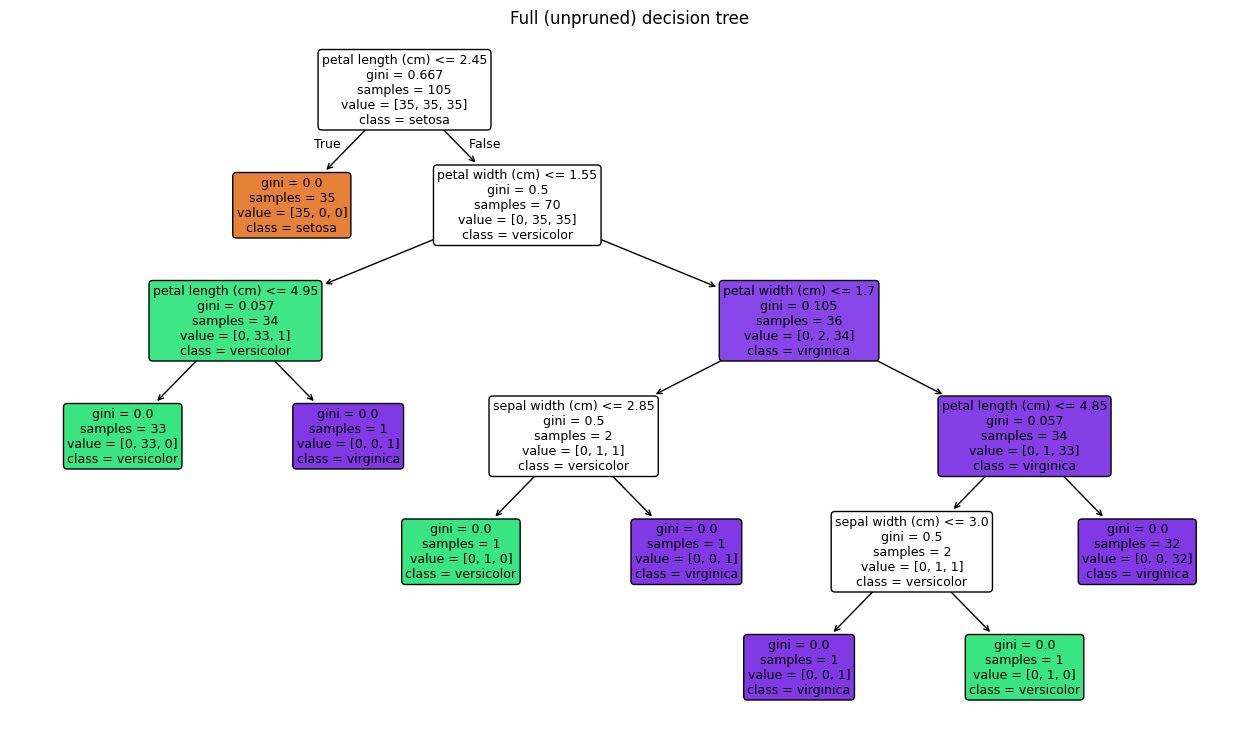

In [5]:
plt.figure(figsize=(16, 9))
plot_tree(full_tree, feature_names=iris.feature_names,
          class_names=iris.target_names, filled=True, rounded=True, fontsize=9)
plt.title('Full (unpruned) decision tree')
plt.show()

## 5. Prune the tree to prevent overfitting
We use **cost-complexity pruning** (`ccp_alpha`). A larger alpha removes more branches. We try different alpha values and pick the best one using the test score.

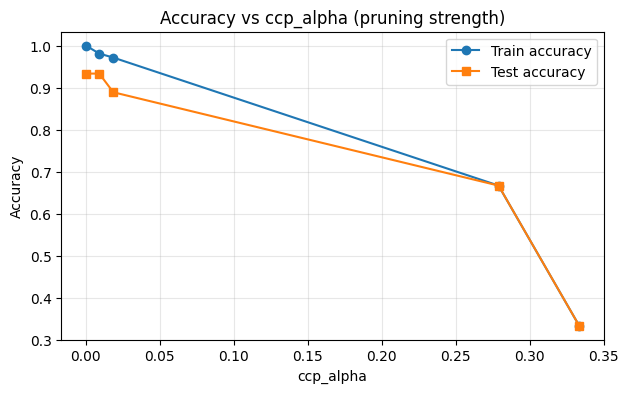

Best ccp_alpha: 0.009 | Test accuracy: 0.9333


In [6]:
path = full_tree.cost_complexity_pruning_path(X_train, y_train)
alphas = np.unique(path.ccp_alphas)

train_scores, test_scores = [], []
for a in alphas:
    t = DecisionTreeClassifier(random_state=42, ccp_alpha=a).fit(X_train, y_train)
    train_scores.append(t.score(X_train, y_train))
    test_scores.append(t.score(X_test, y_test))

plt.figure(figsize=(7, 4))
plt.plot(alphas, train_scores, marker='o', label='Train accuracy')
plt.plot(alphas, test_scores, marker='s', label='Test accuracy')
plt.xlabel('ccp_alpha')
plt.ylabel('Accuracy')
plt.title('Accuracy vs ccp_alpha (pruning strength)')
plt.legend()
plt.grid(alpha=0.3)
plt.show()

# Pick the largest alpha that still gives the best test accuracy (simplest tree)
best_acc = max(test_scores)
best_alpha = max(a for a, s in zip(alphas, test_scores) if s == best_acc)
print('Best ccp_alpha:', round(best_alpha, 4), '| Test accuracy:', round(best_acc, 4))

Depth of pruned tree: 3
Number of leaves    : 4


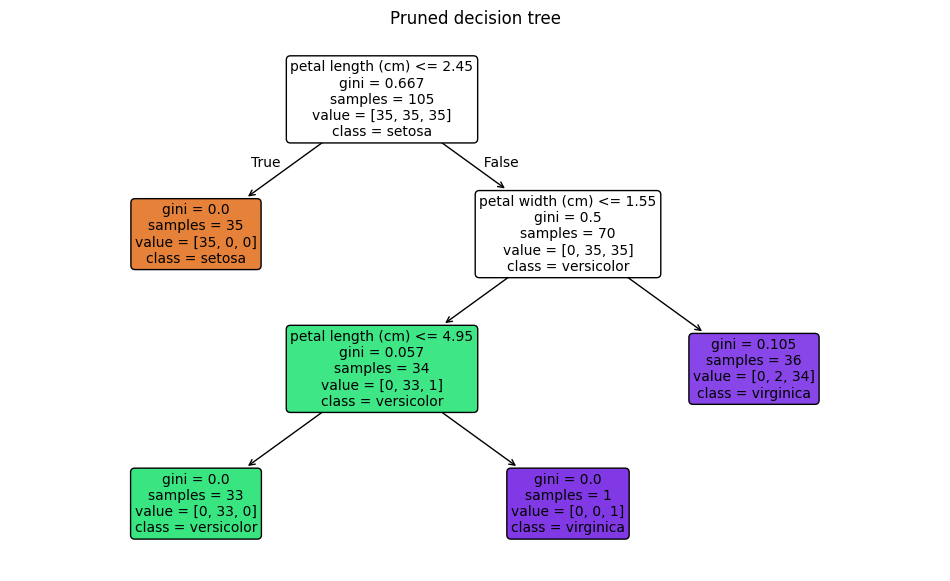

In [7]:
pruned_tree = DecisionTreeClassifier(random_state=42, ccp_alpha=best_alpha)
pruned_tree.fit(X_train, y_train)

print('Depth of pruned tree:', pruned_tree.get_depth())
print('Number of leaves    :', pruned_tree.get_n_leaves())

plt.figure(figsize=(12, 7))
plot_tree(pruned_tree, feature_names=iris.feature_names,
          class_names=iris.target_names, filled=True, rounded=True, fontsize=10)
plt.title('Pruned decision tree')
plt.show()

## 6. Evaluate: full vs pruned tree (accuracy and F1-score)

In [8]:
rows = []
for name, model in [('Full tree', full_tree), ('Pruned tree', pruned_tree)]:
    p = model.predict(X_test)
    rows.append({'Model': name,
                 'Depth': model.get_depth(),
                 'Leaves': model.get_n_leaves(),
                 'Test Accuracy': accuracy_score(y_test, p),
                 'F1 (weighted)': f1_score(y_test, p, average='weighted')})
pd.DataFrame(rows).round(4)

,Model,Depth,Leaves,Test Accuracy,F1 (weighted)
0,Full tree,5,8,0.9333,0.9327
1,Pruned tree,3,4,0.9333,0.9327


In [9]:
print('Classification report (pruned tree):\n')
print(classification_report(y_test, pruned_tree.predict(X_test), target_names=iris.target_names))

Classification report (pruned tree):

              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        15
  versicolor       1.00      0.80      0.89        15
   virginica       0.83      1.00      0.91        15

    accuracy                           0.93        45
   macro avg       0.94      0.93      0.93        45
weighted avg       0.94      0.93      0.93        45



## Feature importance (pruned tree)

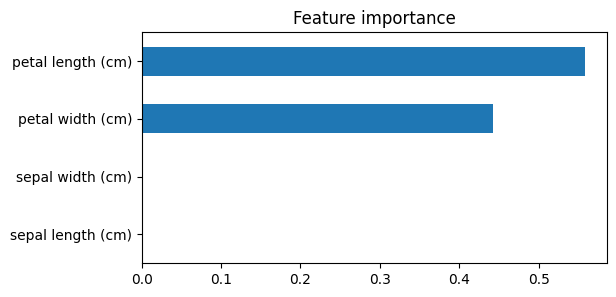

In [10]:
imp = pd.Series(pruned_tree.feature_importances_, index=iris.feature_names).sort_values()
imp.plot(kind='barh', figsize=(6, 3), title='Feature importance')
plt.show()

## Summary
- The unpruned tree fits the training data perfectly but is more complex than needed.
- Pruning (`ccp_alpha`) gives a **smaller, simpler tree** with the same or better test accuracy, so it generalizes better.
- Petal length and petal width are the most important features for separating the species.
- Metrics used: accuracy and F1-score.